In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.TwoArmedBandit import TwoArmedBandit
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Agents.StrategySARSA import stratSARSA
from pyCRLD.Utils.PhasePlot import phaseplot, _data_to_plot, _strategies, _dXisa_s
import numpy as np

In [ ]:
from qDDRLBase import qbase
from qBaseSARSA import qbaseSARSA

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

In [ ]:
def compare_quantiles(env,
                      quantiles,  # quantile list
                      x:tuple,  # which phase space axes to plot along x axes
                      res,  # specify range & resolution
                      NrRandom:int=3,  # how many random (in the other dimensions) stratgies for averaging 
                      traj_len:int=500,  # trajectory length
                      # col:str='LEN',  # color indicates either strength of flow via colormap, otherwise a fixed color name
                      cmap='viridis',  # Colormap
                      acts=None,  # Action descriptions
                      conds=None,  # Conditions descriptions 
                      axes=None,  # Axes to plot into
                      verbose=False,  # shall I talk to you while working?
                      ):  
   

    # Fig and Axes
    states = env.Z
    fig, axes = plt.subplots(1, states, figsize=(states * 3.8, 2.8))
    cmap = mpl.cm.get_cmap(cmap)
    ext = np.linspace(0, 1, len(quantiles))
    colors = cmap(tuple(ext))
    
    # x axis
    xs = res
    zero = np.zeros((len(xs)))

    # The Plots
    for j, q in enumerate(quantiles):
        print(q)
        mae = qbaseSARSA(env, nr_reward_bins=29, discretization_sigma=0.1, 
                         learning_rates=0.05, discount_factors=0.9, 
                         choice_intensities=4, quantile=q, use_prefactor=False)
        for i in range(len(x)): # go through each plot sequentially 
            xinds = (x[0][0], x[1][i], x[2][0])  # fix this later
            
            # obtain the data to plot
            RPEs, dXs = _data_to_plot(mae, res, xinds, traj_len, NrRandom, 
                                      phasespace_items=_strategies, verbose=verbose)
            axes[i].plot(xs, dXs[i, :], color=colors[j], label=str(q))
            axes[i].plot(xs, zero, color="grey", ls='dashed')
        
    # Decorations
    # lens = max(xlens)
    if acts is None:
        acts = [f'act.{i}' for i in range(mae.M)]
        acts = mae.env.Aset
    if conds is None:
        conds = [f'state {i}' for i in range(mae.Z)]
    for i in range(len(x)):
        axes[i].set_title(conds[i])
        axes[i].set_xlabel("prob. act. "+str(xinds[2]))
    axes[0].set_ylabel("dX")
    axes[2].legend(bbox_to_anchor=(1.01, 1.01))
    
    return axes

In [ ]:
# Poor environment
env = TwoArmedBandit(rew=1, pun=-1, pA=0.3, pB=0.1)

In [ ]:
quantiles = [0.15, 0.30, None, 0.70, 0.85]

In [ ]:
x = ([0], [0, 1, 2], [0]) 
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

/tmp/ipykernel_16781/1128652918.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.15
0.3
None
0.7
0.85


array([<Axes: title={'center': 'state 0'}, xlabel='prob. act. 0', ylabel='dX'>,
       <Axes: title={'center': 'state 1'}, xlabel='prob. act. 0'>,
       <Axes: title={'center': 'state 2'}, xlabel='prob. act. 0'>],
      dtype=object)

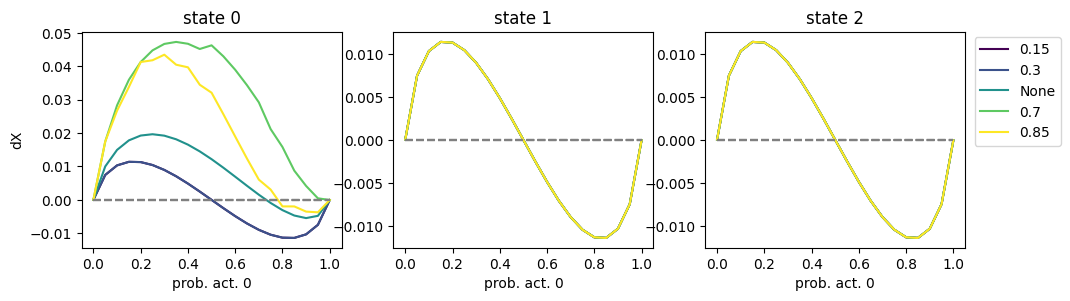

In [ ]:
compare_quantiles(env, quantiles, x, res, NrRandom=4)

In [ ]:
# Rich environment
env = TwoArmedBandit(rew=1, pun=-1, pA=0.9, pB=0.7)

/tmp/ipykernel_16781/1128652918.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = mpl.cm.get_cmap(cmap)


0.15
0.3
None
0.7
0.85


array([<Axes: title={'center': 'state 0'}, xlabel='prob. act. 0', ylabel='dX'>,
       <Axes: title={'center': 'state 1'}, xlabel='prob. act. 0'>,
       <Axes: title={'center': 'state 2'}, xlabel='prob. act. 0'>],
      dtype=object)

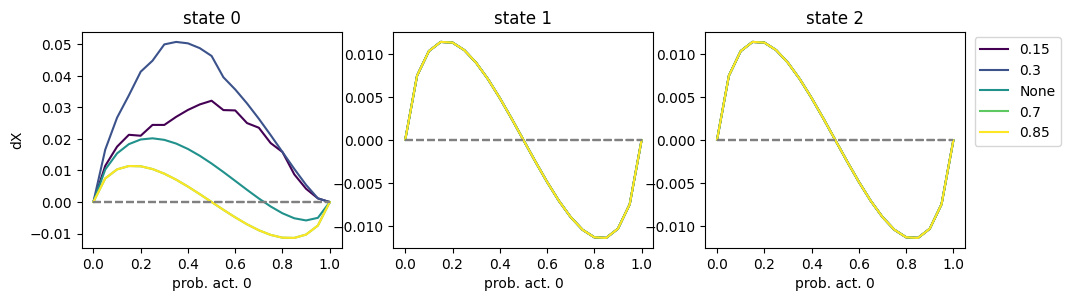

In [ ]:
compare_quantiles(env, quantiles, x, res, NrRandom=1)

In [ ]:
def deltaQinf(p0, p1, x):
    return ((p0 * x - (1 - p0)) / (p0 * x + (1 - p0))) - ((p1 * x - (1 - p1)) / (p1 * x + (1 - p1)))

In [ ]:
x = np.linspace(1, 10, 100)

In [ ]:
p0 = 0.3
p1 = 0.1

In [ ]:
dqinf = deltaQinf(p0, p1, x)

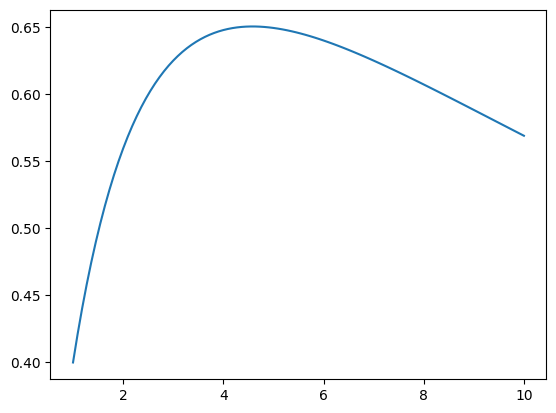

In [ ]:
plt.figure()
plt.plot(x, dqinf)
plt.show()

In [ ]:
p0 = 0.9
p1 = 0.7

In [ ]:
x = np.linspace(0.1, 1, 100)

In [ ]:
dqinf = deltaQinf(p0, p1, x)

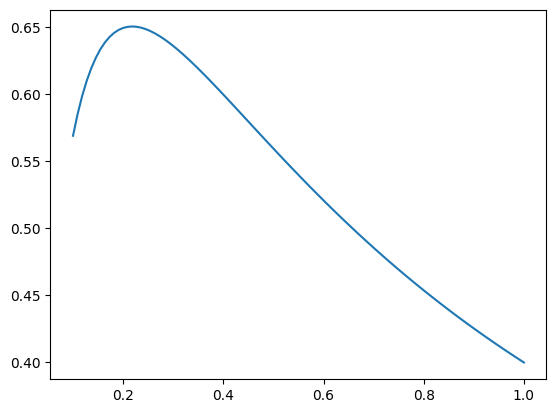

In [ ]:
plt.figure()
plt.plot(x, dqinf)
plt.show()